In [54]:
# load ../data/channel_data.txt as csv lat, long, height

import pandas as pd

df = pd.read_csv(
    "../data/channel_data.txt",
    header=None,
    names=["lat", "long", "height"],
    sep="\t",
)
init_lat, init_long, init_height = df.values[0]

# add init points on top of df


In [ ]:
import numpy as np


def get_distance(lat1, long1, lat2, long2):
    R = 6371

    vector_similarity = (lat1 * lat2 + long1 * long2) / (
        np.sqrt(lat1**2 + long1**2) * np.sqrt(lat2**2 + long2**2)
    )

    distance = R * np.arccos(vector_similarity)
    return distance * 1000

SHould i do it somehow differently, using haversine formula or whatever? I don't think so?

In [57]:
# apply along axis
df["distance"] = df.apply(
    lambda row: get_distance(init_lat, init_long, row["lat"], row["long"]), axis=1
)
df

,lat,long,height,distance
0,31.096216,27.941447,0,0.000000
1,31.078225,27.942138,19,1911.385371
2,31.069844,27.941955,22,2745.006766
3,31.062198,27.941269,23,3446.808292
4,31.055140,27.940582,22,4088.876331
...,...,...,...,...
94,30.447934,28.014740,214,75115.141376
95,30.438462,28.013366,134,75947.195808
96,30.427805,28.012680,7,76981.024568
97,30.420108,28.012680,49,77784.215154


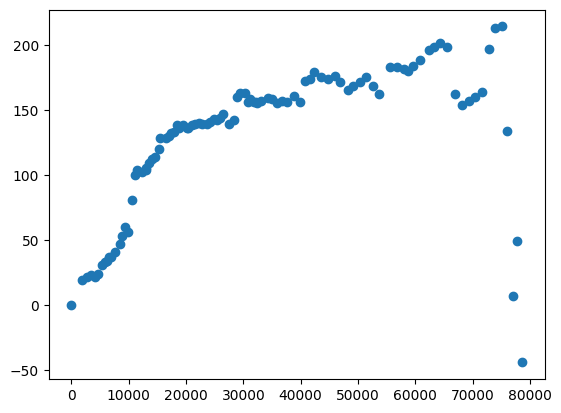

In [58]:
import matplotlib.pyplot as plt


plt.figure()

plt.scatter(df["distance"], df["height"])

plt.show()

In [ ]:
# coefs
ndf = np.array(df)
(df["height"].iloc[1:] - df["height"].iloc[:-1])


# / (df['distance'].iloc[1:] - df['distance'].iloc[:-1])

0     NaN
1     0.0
2     0.0
3     0.0
4     0.0
     ... 
94    0.0
95    0.0
96    0.0
97    0.0
98    NaN
Name: height, Length: 99, dtype: float64

In [103]:
df

,lat,long,height,distance,angle
0,31.096216,27.941447,0,0.000000,0.009940
1,31.078225,27.942138,19,1911.385371,0.003599
2,31.069844,27.941955,22,2745.006766,0.001425
3,31.062198,27.941269,23,3446.808292,-0.001557
4,31.055140,27.940582,22,4088.876331,0.003333
...,...,...,...,...,...
94,30.447934,28.014740,214,75115.141376,-0.096148
95,30.438462,28.013366,134,75947.195808,-0.122844
96,30.427805,28.012680,7,76981.024568,0.052291
97,30.420108,28.012680,49,77784.215154,-0.105527


In [ ]:
from matplotlib.pylab import interp

df["angle"] = (df["height"].shift(-1) - df["height"]) / (
    df["distance"].shift(-1) - df["distance"]
)

max_distance = df["distance"].max()
interpolated_heights = []
distances = []

curr_distance = 0
last_ref_distance_index = 0
while curr_distance < max_distance:
    distances.append(curr_distance)
    if curr_distance >= df.iloc[last_ref_distance_index + 1]["distance"]:
        last_ref_distance_index += 1

    val = df.iloc[last_ref_distance_index]["height"] + df.iloc[last_ref_distance_index][
        "angle"
    ] * (curr_distance - df.iloc[last_ref_distance_index]["distance"])

    curr_distance += 250
    interpolated_heights.append(val)

In [111]:
interpolated_heights

[np.float64(0.0),
 np.float64(2.4851084831374273),
 np.float64(4.9702169662748545),
 np.float64(7.455325449412282),
 np.float64(9.940433932549709),
 np.float64(12.425542415687136),
 np.float64(14.910650898824564),
 np.float64(17.39575938196199),
 np.float64(19.318902428108302),
 np.float64(20.218591428904833),
 np.float64(21.118280429701365),
 np.float64(22.007114880376303),
 np.float64(22.363340950940643),
 np.float64(22.71956702150498),
 np.float64(22.91715565251755),
 np.float64(22.52778881754068),
 np.float64(22.138421982563813),
 np.float64(22.536983425751558),
 np.float64(23.37016862524618),
 np.float64(24.64684937762515),
 np.float64(27.297133081049655),
 np.float64(29.94741678447416),
 np.float64(31.706015222131263),
 np.float64(32.87716128596272),
 np.float64(33.44910154908684),
 np.float64(33.95082798606826),
 np.float64(36.33851278268756),
 np.float64(37.0),
 np.float64(37.36106451854986),
 np.float64(38.67057252864387),
 np.float64(39.98008053873789),
 np.float64(41.4059293

In [ ]:
# ok, simply do the linear interpolation.
for i in range(0, len(df)-1):
    

99